In [1]:
import os, sys
import numpy as np
import random as random
from scipy.linalg import sqrtm
import warnings
warnings.filterwarnings("ignore")

from scipy.stats import multivariate_normal
from sklearn.isotonic import IsotonicRegression

sys.path.insert(0, os.path.abspath(".."))
from Nonparametric.kernel import kernel_density,select_eps_cv
from Nonparametric.utils_model_design import generate_owb_design
from Nonparametric.utils_plot import plot_compare,plot_compare_classical

# Full sibling model

This notebook reproduces the simulation presented in Section 3.1.

## Model Setup

Consider a design with $I$ families of sizes $J = (J_1, \dots, J_I)^T \in \mathbb{R}^I$, totaling $n = \sum_{i=1}^I J_i$ individuals. Let $Y\in\mathbb{R}^{n\times p}$ denote the matrix obtained by stacking the trait measurements for each individual by row. The model can then be compactly expressed as 
$$Y=X\beta+U_1\alpha_1+U_2\alpha_2,$$
where each $\alpha_r$ represents the $r$-th level of random effect, with i.i.d. rows each distributed as $N(0,\Sigma_r)$, $X=\mathbb{1}_n$ is the fixed effects design matrix and $\beta=\mathbb{1}_p^T$ is the fixed effect. The block-diagonal matrix $U_1=\text{diag}(\mathbb{1}_{J_1},\ldots,\mathbb{1}_{J_I})\in\mathbb{R}^{n\times I}$  assigns
each sibling to the corresponding family, where each column $i$ specifies the $J_i$ siblings belonging to family $i$, and $U_2=\text{Id}_n$ is the membership matrix that assigns each individual to the corresponding individual effect.

Consider the unbiased MANOVA estimator of  $\Sigma_1$ given by
$$
    S_n=\frac{1}{p}Y^TBY\in\mathbb{R}^{p\times p},\quad B=\frac{p}{J(I-1)}\pi_1-\frac{p}{J(n-I)}\pi_2,
$$
with $\mathbb{E}(S_n)=\Sigma_1$.

Let 
$$B_1=U_1(U_1^TU_1)^{-1}U_1^T,\quad B_2= \text{Id}_n-U_1(U_1^TU_1)^{-1}U_1^T,$$
and consider the sum of squares matrices
$$
S_1= \frac{1}{p}Y^TB_1Y,\quad S_2= \frac{1}{p}Y^TB_2Y.
$$

Below, we compute the oracle and bona fide nonparametric estimators for the spectrum of $\Sigma_1$ building on the MANOVA estimator $S_n$, and compare them with the classical REML and MANOVA estimators.

We study two scenarios for the spectrum of $\Sigma_1$:

- Linear decay. The eigenvalues satisfy $\tau_i= 1-(i-1)/p$, $i=1,\ldots,p$.
- Step decay. The eigenvalues satisfy $\tau_i=1$ for $i=1,\ldots,p/2$, and $\tau_i=0$ for $i=p/2+1,\ldots,p$.
  
We set $\Sigma_2=\tau_e \text{Id}_p$ and consider two noise levels in each scenario: $\tau_e=1$ and $\tau_e=5$.


In [2]:
p = 100
I = 500
J = 4

U_list, B1_MANOVA, J_list, n = generate_owb_design(I,J,p)
U1,U2= U_list
print("n: ",n)

cache = f'owb_p_{p}_I_{I}_J_{J}'
if not os.path.exists('image/'+cache+'/'):
    os.makedirs('image/'+cache+'/')
cache

n:  2000


'owb_p_100_I_500_J_4'

### MANOVA, REML and oracle estimators

In [3]:
def run_iteration(Sigma1, Sigma2, seed=0):
    np.random.seed(seed)

    alpha1 = multivariate_normal.rvs(mean=np.zeros(p), cov=Sigma1, size=I)
    alpha2 = multivariate_normal.rvs(mean=np.zeros(p), cov=Sigma2, size=n)    
    Y = np.ones((n,p)) + U_list[0]@alpha1 + U_list[1]@alpha2
    
    # MANOVA estimator
    Sn = 1/p*Y.T@B1_MANOVA@Y
    Lambda_M, U = np.linalg.eig(Sn.astype(np.float64))
    isort = np.argsort(Lambda_M)[::-1]
    Lambda_M = Lambda_M[isort]
    U = U[:, isort]    

    # oracle nonparametric estimator
    d_oracle = np.diag(U.T@Sigma1@U)  

    # REML estimator
    U1 = np.kron(np.eye(I), np.ones((1, J)))
    Yb1 = U1 @ Y / J
    Yb2 = np.mean(Y, axis=0).reshape((1, p))
    temp1 = Yb1 - np.repeat(Yb2, I, 0)
    temp2 = Y - np.repeat(Yb1, J, 0)
    mA = J / (I - 1) * temp1.T @ temp1 
    mE = temp2.T @ temp2 / (J - 1) / I
    mE_sqrt = sqrtm(mE)
    mE_inv = np.linalg.inv(mE)
    mE_inv_sqrt = sqrtm(mE_inv)

    Q = mE_inv_sqrt @ mA @ mE_inv_sqrt
    w, v = np.linalg.eig(Q)
    w = w - 1
    w[w <= 0] = 0
    Sigma1_R = mE_sqrt @ v @ np.diag(w) @ v.T @ mE_sqrt / J
    Lambda_R, _ = np.linalg.eigh(Sigma1_R)
    Lambda_R = Lambda_R[np.argsort(Lambda_R)[::-1]]
    return d_oracle,Lambda_M,Lambda_R,Y

## Bona fide estimator
Under the balanced full sibling design, we can analytically solve for the bona fide estimator, with detailed given in Secion 3.

In [4]:
def bona_fide_est(Y):
    Sn = 1/p*Y.T@B1_MANOVA@Y
    Lambda_M, U = np.linalg.eig(Sn.astype(np.float64))
    isort = np.argsort(Lambda_M)[::-1]
    Lambda_M = Lambda_M[isort]
    U = U[:, isort]    
    
    T1 = 1/p*np.diag(U.T@Y.T@B1_MANOVA@U1@U1.T@B1_MANOVA@Y@U)
    T2 = 1/p*np.diag(U.T@Y.T@B1_MANOVA@U2@U2.T@B1_MANOVA@Y@U)

    eps_cv = select_eps_cv(Lambda_M, n)

    f_hat,_ = kernel_density(Lambda_M, n, eps=eps_cv)
    g1_tilde,Hg1_tilde = kernel_density(Lambda_M,n,T=T1,eps=eps_cv)
    g2_tilde,Hg2_tilde = kernel_density(Lambda_M,n,T=T2,eps=eps_cv)

    m_hat_Im = f_hat * np.pi
    b1_hat = np.array([np.pi*complex(Hg1_tilde[i],g1_tilde[i]) for i in range(p)], dtype=np.complex128)
    b2_hat = np.array([np.pi*complex(Hg2_tilde[i],g2_tilde[i]) for i in range(p)], dtype=np.complex128)
    a1_hat = np.zeros_like(b1_hat)
    a2_hat = np.zeros_like(b2_hat)
    

    for i in range(p):
        a2_hat[i] = n/p*(J-1)*(1-1/(J*b2_hat[i]-b1_hat[i]+1))
        a1_hat[i] = -I/p*(1+p/n*a2_hat[i]+1/(b1_hat[i]-1))

    d_hat = a1_hat.imag/m_hat_Im

    iso = IsotonicRegression(increasing=False)
    d_iso = iso.fit_transform(np.arange(1, len(d_hat)+1), d_hat)

    return d_hat, d_iso

### Comparison of estimators

In [5]:
def compute_dist(ppl_eigvals,d_oracle,d_hat,d_iso,Lambda_M,Lambda_R):
    est_list = [d_oracle,d_hat,d_iso,Lambda_M,Lambda_R]
    l2_ppl = [np.sqrt(np.sum((x-ppl_eigvals)**2)) for x in est_list]
    l2_or = [np.sqrt(np.sum((x-d_oracle)**2)) for x in [d_hat,d_iso,Lambda_M]]

    print("l2 norm from Sigma: ")
    print(
        "oracle, bonafide, isotonic, MANOVA, REML: "
        + ", ".join(f"{v:.3f}" for v in l2_ppl)
    )

    print("l2 norm from oracle: ")
    print(
        "bonafide, isotonic, MANOVA: "
        + ", ".join(f"{v:.3f}" for v in l2_or)
    )

### linear decay

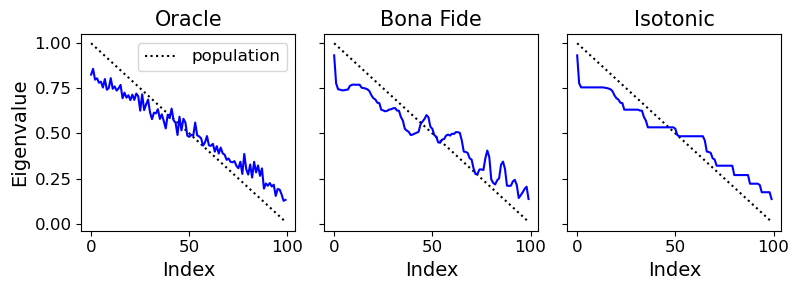

l2 norm from Sigma: 
oracle, bonafide, isotonic, MANOVA, REML: 0.992, 1.116, 1.045, 1.766, 1.735
l2 norm from oracle: 
bonafide, isotonic, MANOVA: 0.512, 0.400, 2.645


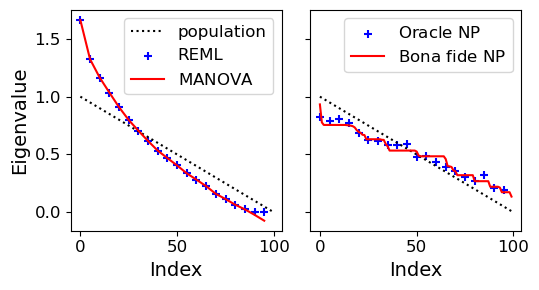

In [6]:
# noise level = 1
tau_e = 1
Sigma1 = np.diag(np.arange(p, 0, -1) / p)
Sigma2 = np.eye(p)*tau_e
d_oracle, Lambda_M,Lambda_R,Y = run_iteration(Sigma1, Sigma2)
d_hat, d_iso = bona_fide_est(Y)
plot_compare(np.diag(Sigma1), d_oracle, d_hat, d_iso, save=cache+f'/bf_noise_{tau_e}_linear')
compute_dist(np.diag(Sigma1), d_oracle, d_hat, d_iso, Lambda_M, Lambda_R)
plot_compare_classical(np.diag(Sigma1), d_oracle, d_iso, Lambda_M, Lambda_R, save=cache+'/bf_classic_linear')

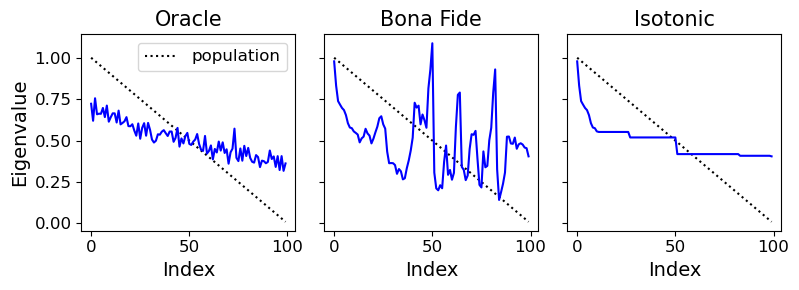

l2 norm from Sigma: 
oracle, bonafide, isotonic, MANOVA, REML: 1.982, 2.903, 2.134, 5.973, 4.888
l2 norm from oracle: 
bonafide, isotonic, MANOVA: 1.843, 0.628, 7.858


In [7]:
# noise level = 5
tau_e = 5
Sigma1 = np.diag(np.arange(p, 0, -1) / p)
Sigma2 = np.eye(p) * tau_e
d_oracle, Lambda_M,Lambda_R,Y = run_iteration(Sigma1, Sigma2)
d_hat, d_iso = bona_fide_est(Y)
plot_compare(np.diag(Sigma1), d_oracle, d_hat, d_iso, save=cache+f'/bf_noise_{tau_e}_linear')
compute_dist(np.diag(Sigma1), d_oracle, d_hat, d_iso, Lambda_M, Lambda_R)

### step decay

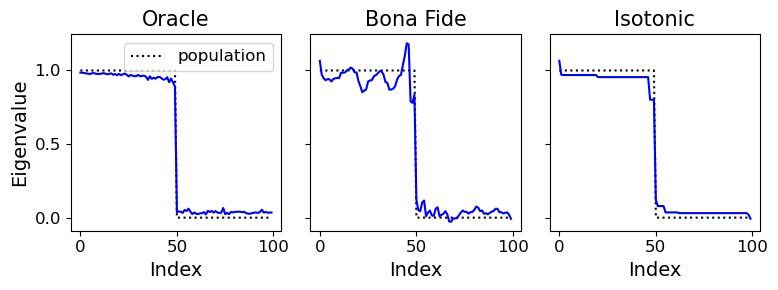

l2 norm from Sigma: 
oracle, bonafide, isotonic, MANOVA, REML: 0.395, 0.718, 0.527, 2.855, 2.798
l2 norm from oracle: 
bonafide, isotonic, MANOVA: 0.590, 0.273, 2.809


In [8]:
# noise level = 1
tau_e=1
Sigma1 = np.diag([1]*int(p/2)+[0]*int(p/2))
Sigma2 = np.eye(p) * tau_e
d_oracle, Lambda_M,Lambda_R,Y = run_iteration(Sigma1, Sigma2)
d_hat, d_iso = bona_fide_est(Y)
plot_compare(np.diag(Sigma1), d_oracle, d_hat, d_iso, save=cache+f'/bf_noise_{tau_e}_step')
compute_dist(np.diag(Sigma1), d_oracle, d_hat, d_iso, Lambda_M, Lambda_R)


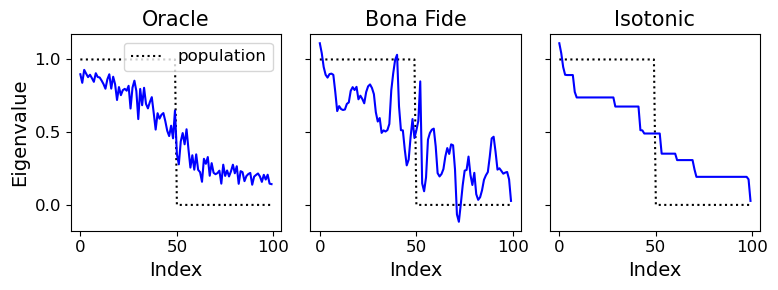

l2 norm from Sigma: 
oracle, bonafide, isotonic, MANOVA, REML: 2.712, 3.321, 2.923, 6.191, 5.237
l2 norm from oracle: 
bonafide, isotonic, MANOVA: 1.698, 0.834, 7.183


In [9]:
# noise level = 5
tau_e=5
Sigma1 = np.diag([1]*int(p/2)+[0]*int(p/2))
Sigma2 = np.eye(p) * tau_e
d_oracle, Lambda_M,Lambda_R,Y = run_iteration(Sigma1, Sigma2)
d_hat, d_iso = bona_fide_est(Y)
plot_compare(np.diag(Sigma1), d_oracle, d_hat, d_iso, save=cache+f'/bf_noise_{tau_e}_step')
compute_dist(np.diag(Sigma1), d_oracle, d_hat, d_iso, Lambda_M, Lambda_R)
